# NaCo - Practicum 1
**Optimization & Simulated Annealing** 

Related lecture: Week1 introduction


## Setup

Please make sure python is installed. It can be downloaded and installed from https://www.python.org/. To check that everything is working properly, open a terminal and type
```bash
    python3 --version
```

### Dependencies
The following dependencies are required during the work group:

__Installation using pip__: ```pip3 install notebook numpy matplotlib```

Jupyter Notebooks are web applications that combine relevant text, mathematical equations, code, and visualizations in one shareable document (such as this one). We hand over the solutions and guides through these Jupyter Notebooks for practical and homework questions involving programming. One could run the code(or skeleton code) and repeat the analysis by playing around with the parameters. In order to run a Jupter server, open a terminal and type:
```bash
    jupyter notebook
```

**Note:** Many IDE's, like VScode have the option to open Jupyter notebook files out of the box. However, I would recommend you try at least once to run this from the terminal, such that you get an idea of how this works under the hood.

### From last week

re-use your himmblau function and plotting function from last week:

In [27]:
import numpy as np
import matplotlib.pyplot as plt

def himmelblau(x, y):
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

def plot_landscape():
    x = np.linspace(-5, 5, 100)
    y = np.linspace(-5, 5, 100)
    z = np.linspace(0, 200, 100)

    X, Y = np.meshgrid(x, y)

    Z = himmelblau(X, Y)

    fig, (ax1, ax2) = plt.subplots(2)
    ax1.contourf(X, Y, Z, levels=100, vmax=300)

    return fig, ax1, ax2

# Exercise 1: implement a random search algorithm

Since we now have an objective function, we can try to find the optimal value. Lets start with the simplest optimization algorithm: **random search** https://en.wikipedia.org/wiki/Random_search. 
By using the 'random' module from numpy, we can sample points uniformly between our lower and upper bounds. If we repeat this $B$ times, and every time compare whether the point is better than the best we have so far, we have a basic optimization algorithm. 

Programmatically, we should have the following structure: \
$x^* = ...$ \
$f(x^*) = \infty$ \
**for** $i \in 1 \dots B$ \
&nbsp;&nbsp;&nbsp;&nbsp;$x \sim \mathcal{U}^{n}(lb, ub)$ \
&nbsp;&nbsp;&nbsp;&nbsp;**if** $f(x) < f(x^*)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$f(x^*) = f(x)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$x^* = x$ 

In this example, $n$ denotes the dimension of the problem, which is 2 in this case and $\mathcal{U}^{n}(lb, ub)$ the generation of an $n$ dimensional vector of uniformly distributed random numbers, where each element is in $[lb, ub]$. 

**Note** don't forget to set a random seed!

In [4]:
# tips: You can unpack an array with *
# you can make use of that to call your objective function with an array instead of x and y -> himmelblau(*x)
x = [1, 2]
print(*x)

1 2


/tmp/ipykernel_17078/720809655.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


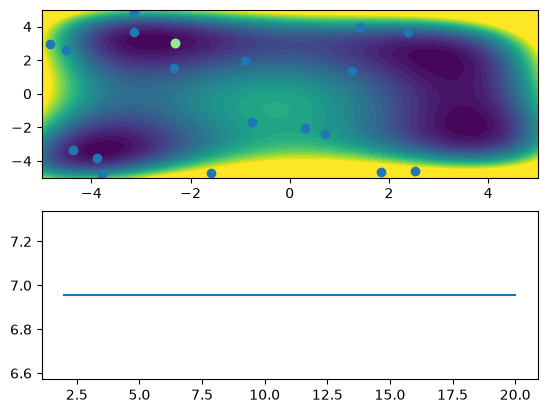

In [52]:
import random
from datetime import datetime

random.seed(datetime.now().strftime("%m/%d/%Y, %H:%M:%S"))

B = 20

lb = -5
ub = 5

n = 2

xb = []
fb = float("inf")

points_x = []
points_y = []
final_points_x = []
final_points_y = []
fitness_path_y = []
fitness_path_x = []
fitness_path_x.append(0)
fitness_path_y.append(fb)

for i in range(1, B):
    x = [random.randrange(lb * 100, ub * 100)/100,random.randrange(lb * 100, ub * 100)/100]
    fitness = himmelblau(x[0], x[1])
    points_x.append(x[0])
    points_y.append(x[1])
    if (fitness < fb):
        final_points_x.append(x[0])
        final_points_y.append(x[1])
        fb = fitness
        xb = x

    fitness_path_x.append(i + 1)
    fitness_path_y.append(fb)
    


fig, ax1, ax2 = plot_landscape()
ax1.scatter(points_x, points_y)
ax1.scatter(final_points_x, final_points_y, color="red")
ax1.scatter(xb[0], xb[1], color="lightgreen")

ax2.plot(fitness_path_x, fitness_path_y)

fig.show()


### Plotting the algorithm
We can modify this algorithm to keep track of the points we evaluate, by storing the evaluated points in a **list** and plot them on the function. 

Use a scatter plot after the contour plot to overlay the points.
You can do this twice: once for the history, and once for the final point, so we see 
where we ended up after the search.

Try to play a bit with the plotting settings to make a nice looking visualization, and again, make a function of the plotting utility so that we can reuse it later. 

### Plotting the algorithm (v2)
Instead of only considering our x-values, plot the y-values in a **subplot**. To do this, please make sure you also track these values when the algorithms is running in a seperate list. Then, modify our previously defined plotting function, to make two subplots, one that plots the contour plot, and another, **a line plot**, which plots the progression of the y values. 

**Note** for plotting the y values, make sure to also keep track of the iteration counter, such that the correct time is shown on the x-axis. 

# Exercise 3: A Random Walk

We can modify our random search to not sample new points uniformly, but instead mutate the current best point slightly. This transforms the process of the algorithm from completly uniform random, to a **random walk**. This can be done by using a multivariate normal (=Gaussian) distribution. See https://numpy.org/doc/1.16/reference/generated/numpy.random.normal.html#numpy.random.normal. 

This changes the algorithm to the following: \
$x^* \sim \mathcal{U}^{n}(lb, ub)$ \
$f(x^*) = \infty$ \
**for** $i \in 1 \dots B$ \
&nbsp;&nbsp;&nbsp;&nbsp;$z \sim \mathcal{N}^{n}(0, 1)$ \
&nbsp;&nbsp;&nbsp;&nbsp;$x = x^* + \sigma z$ \
&nbsp;&nbsp;&nbsp;&nbsp;**if** $f(x) < f(x^*)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$f(x^*) = f(x)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$x^* = x$ \
  
Here $\mathcal{N}^{n}(0, 1)$ denotes an $n$-dimensional gaussian distribution.

Your task is to modify the code to this algorithm, and use the same plotting as before to see the differences in search behavior.

**Note** the introduction of the $\sigma$ parameter, which controls the step size of the algorithm. This should be chosen with care. To large values will make the algorithm jump to far, while to small jumps will cause it to stagnate. 

**Note** One important thing to take into account here is that we want to ensure new candidates are still within our bounds. For this, you can use the 'clip' function from numpy. 

**Note** this is not a true random walk, since we only accept improved solutions.

/tmp/ipykernel_17078/1622161817.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


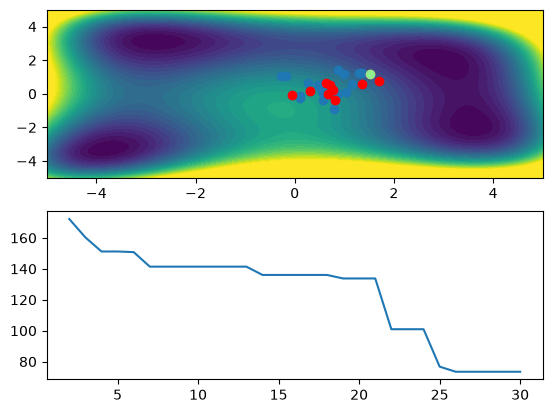

In [54]:

random.seed(datetime.now().strftime("%m/%d/%Y, %H:%M:%S"))
step_size = 0.4

B = 30

lb = -5
ub = 5

n = 2

xb = [0,0]
fb = float("inf")

points_x = []
points_y = []
final_points_x = []
final_points_y = []
fitness_path_y = []
fitness_path_x = []
fitness_path_y.append(fb)
fitness_path_x.append(0)

for i in range(1, B):
    x = [xb[0] + step_size * np.random.normal(0,1), xb[1] + step_size * np.random.normal(0,1)]
    
    fitness = himmelblau(x[0], x[1])
    points_x.append(x[0])
    points_y.append(x[1])
    if (fitness < fb):
        final_points_x.append(x[0])
        final_points_y.append(x[1])
        fb = fitness
        xb = x

    fitness_path_x.append(i + 1)
    fitness_path_y.append(fb)
    


fig, ax1, ax2 = plot_landscape()
ax1.scatter(points_x, points_y)
ax1.scatter(final_points_x, final_points_y, color="red")
ax1.scatter(xb[0], xb[1], color="lightgreen")

ax2.plot(fitness_path_x, fitness_path_y)

fig.show()



# Exercise 4: Accepting worse solutions
Up until now, we only `keep` the current solution when it is better than the current best solution. Now, implement a random chance to accept a worse solution.

This changes the algorithm to the following: \
$x^* \sim \mathcal{U}^{n}(lb, ub)$ \
$f(x^*) = \infty$ \
**for** $i \in 1 \dots B$ \
&nbsp;&nbsp;&nbsp;&nbsp;$z \sim \mathcal{N}^{n}(0, 1)$ \
&nbsp;&nbsp;&nbsp;&nbsp;$x = x^* + \sigma z$ \
&nbsp;&nbsp;&nbsp;&nbsp;**if** $f(x) < f(x^*)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$f(x^*) = f(x)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$x^* = x$ \
&nbsp;&nbsp;&nbsp;&nbsp;**else if** $\mathcal{U}(0, 1) < \eta$:
\
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$f(x^*) = f(x)$ \
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$x^* = x$ 

Please modify the code to accomodate the changes and the same plotting as before to see the differences in search behavior.



**Note** the introduction of $\eta$ which controls the chance of randomly accepting a worse solution. Try to play a bit with different values to get an idea of its influence. 

/tmp/ipykernel_17078/1703304400.py:56: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


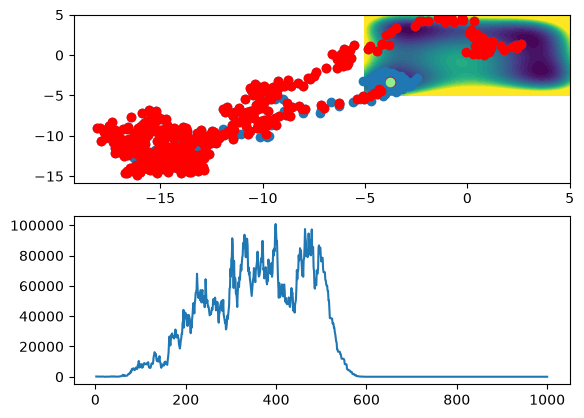

In [ ]:
random.seed(datetime.now().strftime("%m/%d/%Y, %H:%M:%S"))
step_size = 0.4
exploration_rate = 0.9

B = 1000

lb = -5
ub = 5

n = 2

xb = [0,0]
fb = float("inf")

points_x = []
points_y = []
final_points_x = []
final_points_y = []
fitness_path_y = []
fitness_path_x = []
fitness_path_y.append(fb)
fitness_path_x.append(0)

for i in range(1, B):
    x = [xb[0] + step_size * np.random.normal(0,1), xb[1] + step_size * np.random.normal(0,1)]
    
    fitness = himmelblau(x[0], x[1])
    points_x.append(x[0])
    points_y.append(x[1])
    if (fitness < fb):
        final_points_x.append(x[0])
        final_points_y.append(x[1])
        fb = fitness
        xb = x
    elif (random.randrange(0,1) < exploration_rate):
        final_points_x.append(x[0])
        final_points_y.append(x[1])
        fb = fitness
        xb = x

    if ((i % 50) == 0  and  exploration_rate != 0):
        exploration_rate = exploration_rate - 0.1

    fitness_path_x.append(i + 1)
    fitness_path_y.append(fb)
    


fig, ax1, ax2 = plot_landscape()
ax1.scatter(points_x, points_y)
ax1.scatter(final_points_x, final_points_y, color="red")
ax1.scatter(xb[0], xb[1], color="lightgreen")

ax2.plot(fitness_path_x, fitness_path_y)

fig.show()

# Exercise 5: Temperature 

In **simulated annealing** (SA), the temperature is a key parameter that controls the probability of accepting worse solutions during the optimization process. As seen during the lecture, Simulated annealing is inspired by the physical process of annealing, where a material is heated and then slowly cooled to reach a stable, low-energy state. 

The idea is, initially, at the start of the algorithm, the temperature is set high, allowing the system to explore the solution space more freely. As the algorithm progresses, the **temperature gradually decreases**, reducing the probability of accepting worse solutions.

The probability of accepting a worse solution is determined by the **Metropolis criterion**:
$P(\Delta f, T) = \exp \frac{-\Delta f}{T}$

In our algorithm, this becomes:

$x^* \sim \mathcal{U}^{n}(lb, ub)$\
$f(x^*) = \infty$\
$T = ...$\
**for** $i \in 1 \dots B$\
&nbsp;&nbsp;&nbsp;&nbsp;$z \sim \mathcal{N}^{n}(0, 1)$\
&nbsp;&nbsp;&nbsp;&nbsp;$x = x^* + \sigma z$\
&nbsp;&nbsp;&nbsp;&nbsp;**if** $f(x) < f(x^*)$\
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$f(x^*) = f(x)$\
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$x^* = x$\
&nbsp;&nbsp;&nbsp;&nbsp;**else if** $\mathcal{U}(0, 1) < P(f(x) - f(x^*), T)$\
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$f(x^*) = f(x)$\
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$x^* = x$\
&nbsp;&nbsp;&nbsp;&nbsp;$T = T - \Delta T$

Modify the algorithm and plot the search behaviour. 

**Note** the introduction of $T$ and $\Delta T$ which denote the value of the temperature and the **cooling rate**. The cooling rate is critical in balancing exploration and exploitation for finding the global optimum. Again, try to play a bit with different values for $T$ and  $\Delta T$ to see the differences in behavior.

best fitness:  5.248037394404318


/tmp/ipykernel_17078/3684089887.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


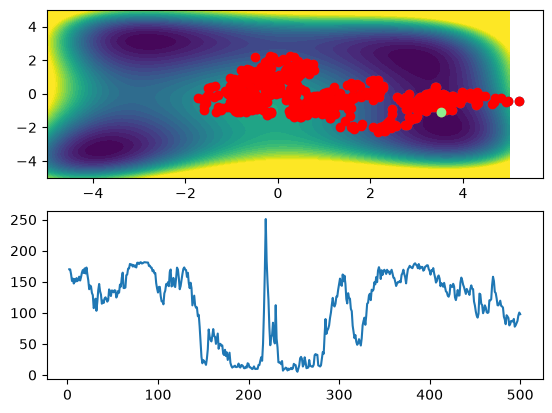

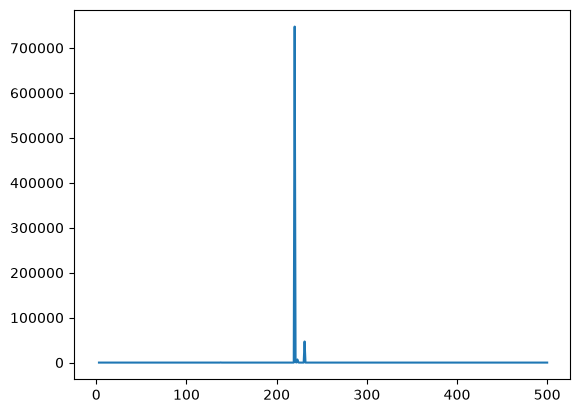

In [205]:
random.seed(datetime.now().strftime("%m/%d/%Y, %H:%M:%S"))
step_size = 0.2
dT = 5
T = 100

B = 500

lb = -5
ub = 5

n = 2

xb = [0,0]
fb = float("inf")

points_x = []
points_y = []
final_points_x = []
final_points_y = []
fitness_path_y = []
fitness_path_x = []
fitness_path_y.append(fb)
fitness_path_x.append(0)
expvalu = []
expvalu.append(0)

real_best_x = []
real_best_fit = float("inf")

for i in range(1, B):
    x = [xb[0] + step_size * np.random.normal(0,1), xb[1] + step_size * np.random.normal(0,1)]
    fitness = himmelblau(x[0], x[1])
    points_x.append(x[0])
    points_y.append(x[1])
    expvalu.append(np.exp(-(fitness - fb)/T))
    if (fitness < fb):
        final_points_x.append(x[0])
        final_points_y.append(x[1])
        fb = fitness
        xb = x
    elif (random.randrange(0,1) < np.exp(-(fitness - fb)/T)):
        final_points_x.append(x[0])
        final_points_y.append(x[1])
        fb = fitness
        xb = x

    if (fitness < real_best_fit):
        real_best_fit = fitness
        real_best_x = x

    fitness_path_x.append(i + 1)
    fitness_path_y.append(fb)
    if ((T - dT) > 0):
        T = T - dT
        

print("best fitness: ", real_best_fit)

fig, ax1, ax2 = plot_landscape()
ax1.scatter(points_x, points_y)
ax1.scatter(final_points_x, final_points_y, color="red")
ax1.scatter(real_best_x[0], real_best_x[1], color="lightgreen")

ax2.plot(fitness_path_x, fitness_path_y)

fig, ax1 = plt.subplots()
ax1.plot(fitness_path_x, expvalu)


fig.show()

## Excersise 6: clean up the code and turn it into a class

Python is an object-oriented language, and thus using classes is quite common to allow our code to be easier to re-use. For more infomration on classes in python, please see: https://www.w3schools.com/python/python_classes.asp

We can now turn our SA-code into a class. 
We will make use only of the default functions: `__init__` for initialization, which we can use to e.g. set a starting temperature, and `__call__` for doing the optimization. This call function will get passed the objective function, and return the best found solution. 

It is up to you to decide where you pass in the variables relating to problem dimensionality and bounds.

# Repeat, repeat, repeat ...
With the class defined, we can instantiate it to make an object which we can use to do the optimization. With this in place, we can now try different objective functions. For now, run the algorithm multiple times on the same problem to see how different each run is, try to experiment with different settings.

More information about the process of analyzing and comparing the performance of different optimization algorithms will follow in one of the next lectures...

In order to plot multiple runs in the same plot, we have to be carefull at a few things:
1. Re-use the same axes and figure
2. Make sure to not plot the contour everytime
3. Set different colors for each run

You may need to adapt your plotting function to do that.